In [89]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
%matplotlib inline
from glob import glob
from astropy.io import fits
from astropy.table import Table
import corner

In [61]:
fontsize=12
font ={"size": fontsize, "family": 'monospace'}
plt.rc("font", **font)

### Read in parameters

In [84]:
t = Table.read('data/SMIDGE_BEAST-final_w_obscat_avsnr6_cuts_stats.fits')
print(len(t))
ra = t["RA"]
dec = t["DEC"]
av = t["Av_p50_1"]
temp = t["logT_p50_1"]
print(np.median(av))
t_smc_av = t[av > 0.18]
t_high_ext = t[av > np.median(av)]
t_hot_stars = t[temp >= 4.]
t_B0_SpT = t[temp >= 4.4]
temp_high_ext = t_high_ext["logT_p50_1"]
temp_B0 = t_B0_SpT["logT_p50_1"]
print(len(t_O_SpT))
print(max(temp))
lent = len(t)
len_h_ext = len(t_high_ext)
len_hot = len(t_hot_stars)
print("SMC-only ext", len_h_ext)
print("O-type only", len_hot)
print(10**4.4)

44065
0.7920817059952906
6
4.4626571584096375
SMC-only ext 22032
O-type only 6613
25118.864315095823


### Plotting

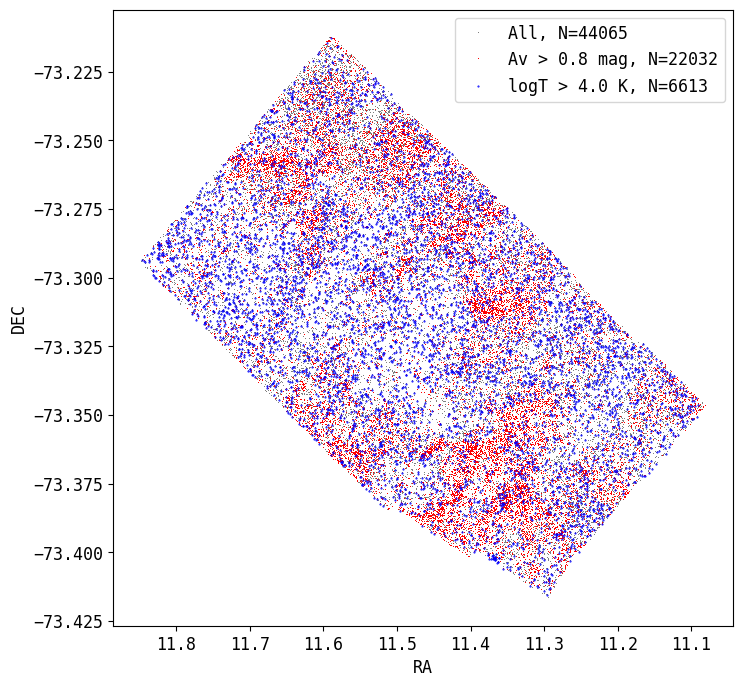

In [62]:
plt.figure(figsize=(8,8))
plt.plot(ra, dec, ',', c='gray', ls='', 
         label='All, N={}'.format(lent))
plt.plot(t_high_ext["RA"], t_high_ext["DEC"], 'r,', ls='', 
         label='Av > 0.8 mag, N={}'.format(len_h_ext))
plt.plot(t_hot_stars["RA"], t_hot_stars["DEC"], 'b.', ms=1, ls='', 
         label='logT > 4.0 K, N={}'.format(len_hot))
plt.legend()
plt.xlabel("RA")
plt.ylabel("DEC")
ax=plt.gca()
ax.invert_xaxis()

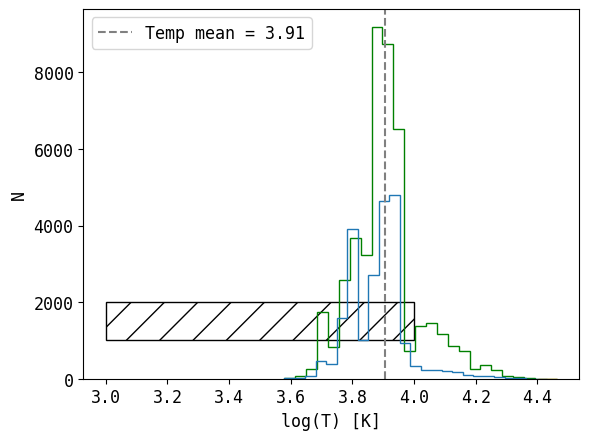

In [91]:
plt.figure()
plt.hist(temp, histtype='step', bins=25, color='g')
plt.hist(temp_high_ext, histtype='step', bins=25)
ax=plt.gca()
ax.add_patch(Rectangle((3, 1000), 1, 1000, fill=False, hatch='/'))
plt.hist(temp_B0, histtype='step', bins=25)
plt.xlabel('log(T) [K]')
plt.ylabel('N')
tm = np.mean(temp)
plt.axvline(tm, 0, max(temp), ls='--', color='gray', 
           label='Temp mean = {}'.format(np.around(tm, decimals=2)))
plt.legend()